In [131]:
import sys
import os
from pathlib import Path

project_root = Path(os.getcwd()).parent 
sys.path.insert(0, str(project_root))

### 02. Анализ показателей сна 

> Люди с каким хронотипом преобладают в данных? Правда ли «совы» спят меньше, а «жаворонки» продуктивнее? Есть ли те, кто спит аномально большое количество часов и почему? Есть ли те, кто спит мало и/или чей сон не является качественным и как это влияет на их работу, учебу и психическое состояние? Склонны ли люди, которые спят плохо, переедать и набирать вес? 

#### 02.1. Проверка корректности показателя часов сна

In [ ]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt     
import seaborn as sns 
import src.constants as cn 
from processed_df_loading import df 

plt.rcParams['font.family'] = 'Arial'

print(df.sleep_hours.nlargest(25).to_list())

# Найдены значения, говорящие о том, что человек спал 22 часа. Вероятнее всего, это является ошибкой в данных, и за неимением дополнительной информации их можно заменить на NaN во избежание некорректных результатов анализа.
df.sleep_hours = np.where(df.sleep_hours == 22, np.nan, df.sleep_hours)

[12.5, 12.5, 12.5, 12.5, 12.5, 12.5, 12.5, 12.5, 12.5, 12.5, 12.41, 12.33, 12.33, 12.31, 12.22, 12.21, 12.21, 12.2, 12.2, 12.13, 12.11, 12.1, 12.09, 12.07, 12.05]


#### 02.2. Анализ хронотипов 

In [133]:
df_02 = df.copy()

chronotype_qroups = df_02.groupby('chronotype').agg(
    group_qty=('participant_id', 'nunique'),
    avg_sleep_hours=('sleep_hours', 'mean'), 
    avg_productivity_score=('productivity_score_0_100', 'mean')
).round(2)

display(chronotype_qroups)

,group_qty,avg_sleep_hours,avg_productivity_score
chronotype,,,
evening,195,6.77,64.88
intermediate,271,7.04,71.41
morning,156,7.04,74.57


#### 02.3. Поиск людей с аномально высоким количеством сна 

> В [исследовании CDC](https://stacks.cdc.gov/view/cdc/90266/) на базе NHANES (2013–2016) сон классифицируется как очень долгий, если он длится 9 часов и более.

Количество людей с аномально долгим сном: 1681


,long_sleep,normal_sleep
sleep_quality_1_10,5.06,6.97
exercise_minutes,11.70,40.11
workout_intensity_1_10,3.61,5.04
calories_kcal,2462.03,2583.53
study_hours,3.04,2.82
work_hours,2.76,3.09
stress_1_10,5.70,3.59
mental_strain_0_10,4.39,2.69


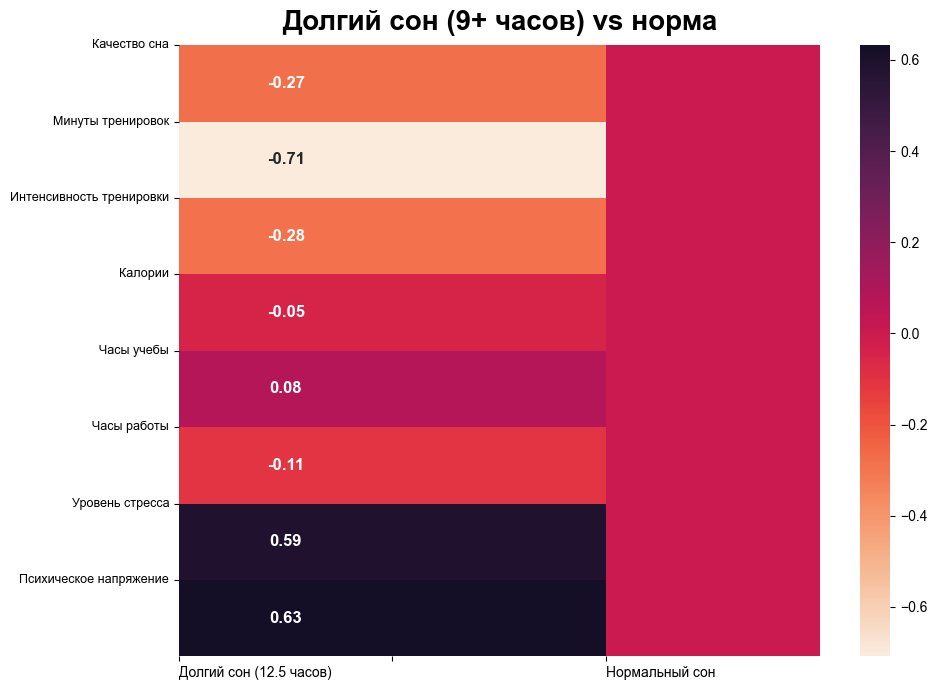

In [134]:
avg_sleep_time = df_02.groupby('participant_id').sleep_hours.mean().to_frame()
avg_sleep_time_9_more_id = avg_sleep_time.loc[avg_sleep_time.sleep_hours >= 9].index
sleep_long_anomaly = df_02.loc[df_02.participant_id.isin(avg_sleep_time_9_more_id)]
normal_sleep = df_02.loc[df_02.participant_id.isin(avg_sleep_time.loc[avg_sleep_time.sleep_hours.between(7, 9)].index)]
print(f'Количество людей с аномально долгим сном: {sleep_long_anomaly.shape[0]}')

factors = dict.fromkeys([
    'sleep_quality_1_10',  
    'exercise_minutes', 'workout_intensity_1_10', 
    'calories_kcal', 
    'study_hours', 'work_hours',  
    'stress_1_10', 'mental_strain_0_10', 
], 'mean')

anomaly_stats = pd.concat([sleep_long_anomaly.agg(factors), (nf := normal_sleep.agg(factors))], axis=1).round(2).rename(columns={0: 'long_sleep', 1: 'normal_sleep'})  # ? function 
display(anomaly_stats)

# нормализация и подготовка датафрейма для отрисовки хитмэпа 
normalized_anomaly_stats = anomaly_stats.div(anomaly_stats.normal_sleep, axis=0) - 1
normalized_anomaly_stats.insert(1, 'duplicate', normalized_anomaly_stats.long_sleep)


fig, ax = plt.subplots(figsize=(10, 7))

annot = [[round(n, 2), '', ''] for n, _, _ in normalized_anomaly_stats.values]

sns.heatmap(
    normalized_anomaly_stats,
    center=0, cmap='rocket_r', 
    annot=annot, fmt='', annot_kws={'fontweight': 'bold', 'fontsize': 12}, 
    ax=ax
    )

ax.set_yticks(
    range(normalized_anomaly_stats.shape[0]), 
    labels=['Качество сна', 'Минуты тренировок', 'Интенсивность тренировки', 'Калории', 'Часы учебы', 'Часы работы', 'Уровень стресса', 'Психическое напряжение'], fontsize=9
    )
ax.set_xticks(
    range(normalized_anomaly_stats.shape[1]), 
    labels=['Долгий сон (12.5 часов)', '', 'Нормальный сон'], 
    ha='left', fontsize=10
)
ax.set_title('Долгий сон (9+ часов) vs норма', fontsize=20, fontweight='bold', pad=11)

plt.tight_layout()

#### 02.4. Поиск людей с аномально низким количеством сна 

,short_sleep,normal_sleep
study_hours,4.92,2.82
work_hours,4.64,3.09
stress_1_10,8.74,3.59
mental_strain_0_10,7.80,2.69


Количество калорий у людей, спящих менее 5 часов:
Среднее значение: 2858.0
Медианное значение: 2817.0
Максимальное значение: 6039.0


,participant_id,start_weight,end_weight,weight_diff,days_qty
600,P0006,73.2,79.0,5.8,120
1560,P0014,93.7,99.6,5.9,120
16560,P0139,72.7,82.9,10.2,120
20040,P0168,70.7,78.4,7.7,121
32160,P0269,77.8,85.6,7.8,119
32880,P0275,84.3,93.7,9.4,120
33000,P0276,75.7,82.5,6.8,120
46200,P0386,86.9,93.6,6.7,120
46920,P0392,57.3,66.0,8.7,120
48240,P0403,69.5,64.1,-5.4,120


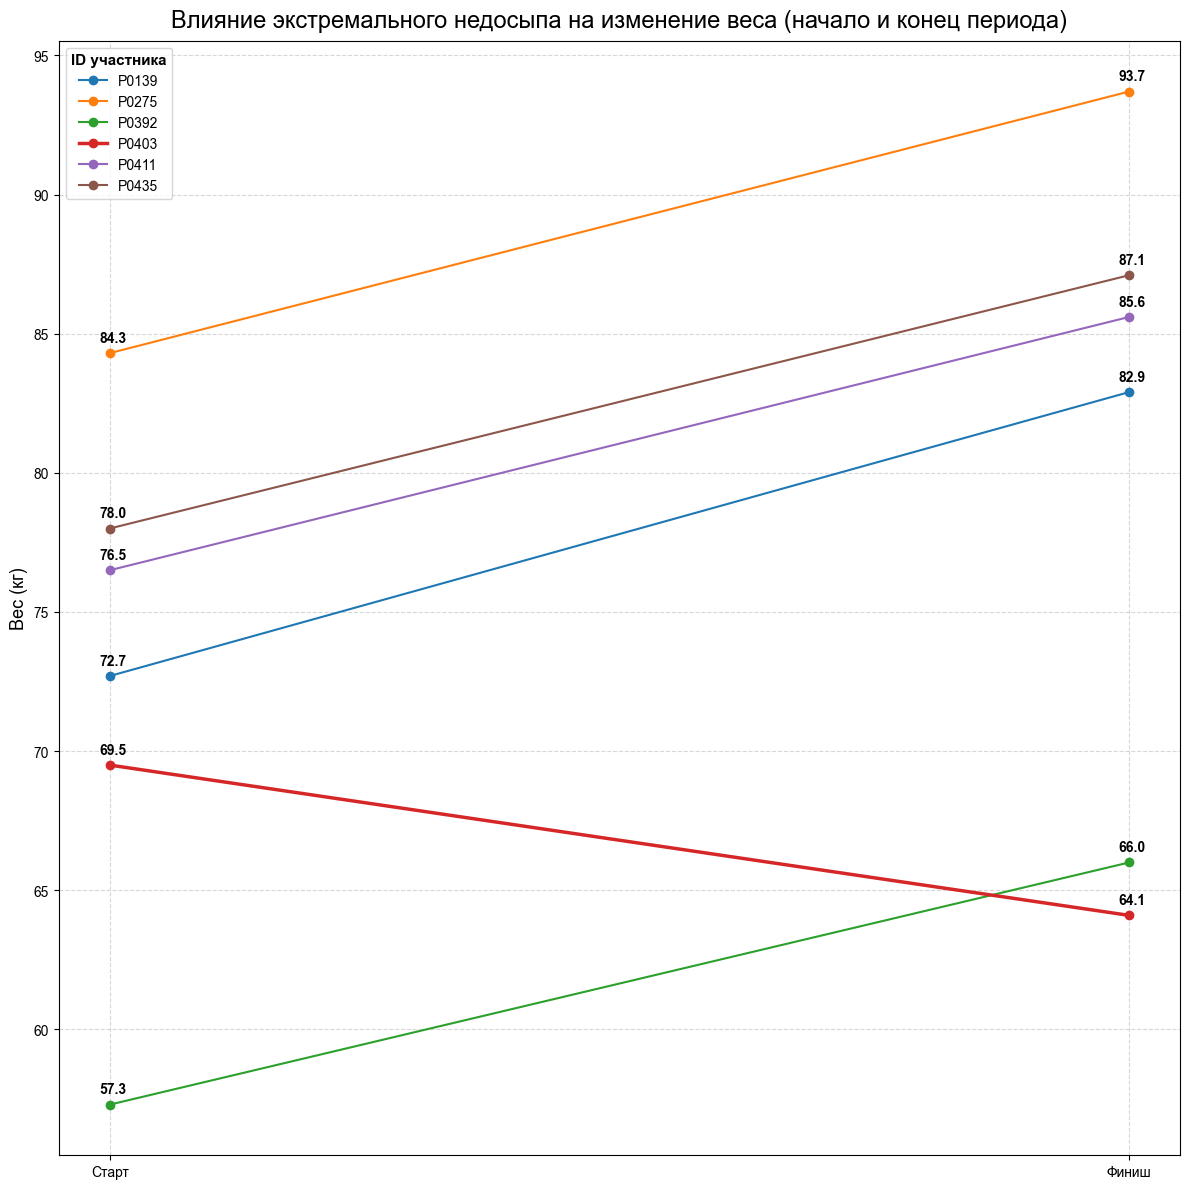

In [ ]:
# поиск тех, чей средний сон <5 
avg_sleep_time_less_5_id = avg_sleep_time.loc[avg_sleep_time.sleep_hours < 5].index
avg_sleep_time_less_5 = df_02.loc[df_02.participant_id.isin(avg_sleep_time_less_5_id)]

# влияние на учебу, работу и стресс 
cons = dict.fromkeys(['study_hours', 'work_hours', 'stress_1_10', 'mental_strain_0_10'], 'mean')
cons_stat = pd.concat([avg_sleep_time_less_5.agg(cons), normal_sleep.agg(cons)], axis=1)
display(cons_stat.round(2).rename(columns={0: 'short_sleep', 1: 'normal_sleep'}))

# влияние на количество калорий 
print('Количество калорий у людей, спящих менее 5 часов:')
print(f'Среднее значение: {(cal := avg_sleep_time_less_5.calories_kcal).mean().round()}')
print(f'Медианное значение: {cal.median()}')
print(f'Максимальное значение: {cal.max()}')

# влияние на набор веса 
avg_sleep_time_less_5_c = avg_sleep_time_less_5.copy()
avg_sleep_time_less_5_c['day_num'] = avg_sleep_time_less_5.groupby('participant_id')['date'].transform(lambda i: i.rank(method='first'))
avg_sleep_time_less_5_c['day_num_reversed'] = avg_sleep_time_less_5.groupby('participant_id')['date'].transform(lambda i: i.rank(method='first', ascending=False))
avg_sleep_time_less_5_c = avg_sleep_time_less_5_c.loc[(avg_sleep_time_less_5_c.day_num == 1) | (avg_sleep_time_less_5_c.day_num_reversed == 1)]
avg_sleep_time_less_5_c['end_weight'] = avg_sleep_time_less_5_c.groupby('participant_id').weight_kg.transform(lambda i: i.shift(-1))
avg_sleep_time_less_5_c = avg_sleep_time_less_5_c[['participant_id', 'weight_kg', 'end_weight', 'day_num_reversed']].dropna()
avg_sleep_time_less_5_c = avg_sleep_time_less_5_c.rename(columns={'day_num_reversed': 'days_qty', 'weight_kg': 'start_weight'})
avg_sleep_time_less_5_c.days_qty = avg_sleep_time_less_5_c.days_qty.astype(int)
avg_sleep_time_less_5_c['weight_diff'] = avg_sleep_time_less_5_c.end_weight - avg_sleep_time_less_5_c.start_weight
display(avg_sleep_time_less_5_c.reindex(columns=['participant_id', 'start_weight', 'end_weight', 'weight_diff', 'days_qty']))


fig, ax = plt.subplots(figsize=(12, 12))

# топ-5 тех, кто набрал больше всего + 1, кто сбросил 
avg_sleep_time_less_5_c['weight_gain_rank'] = avg_sleep_time_less_5_c.weight_diff.rank(method='first', ascending=False)
avg_sleep_time_less_5_c_graph = avg_sleep_time_less_5_c.loc[(avg_sleep_time_less_5_c.weight_gain_rank <= 5) | (avg_sleep_time_less_5_c.weight_diff < 0)]

for i, (label, row) in enumerate(avg_sleep_time_less_5_c_graph.iterrows()): 
    sw, ew = row.start_weight, row.end_weight
    ax.plot(
        (0, 1), (sw, ew), 
        label=row.participant_id, marker='o', 
        lw = 1.5 if sw < ew else 2.5
    )
    ax.annotate(
        text=sw, xy=(0 - .01, sw + .4), 
        fontweight='bold'
    )
    ax.annotate(
        text=ew, xy=(1 - .01, ew + .4), 
        fontweight='bold'
    )
    
ax.legend(title='ID участника', title_fontproperties={'weight': 'bold', 'size': 11})
ax.set_xticks(range(2), labels=['Старт', 'Финиш'])
ax.set_ylabel('Вес (кг)', fontsize=13)
ax.set_title('Влияние экстремального недосыпа на изменение веса (начало и конец периода)', **cn.TITLE_PARAMS)
ax.grid(ls='--', alpha=.5)

plt.tight_layout()

#### 02.5. Выводы 
**Хронотипы.**  
В ходе проведенного анализа было обнаружено преобладание людей с промежуточным хронотипом (271 чел. против 195 «сов» и 156 «жаворонков»). Данное наблюдение ожидаемо и объясняется тем, что людям часто приходится менять свое время отхода ко сну и пробуждения, чтобы подстроиться под внешние обстоятельства.  
Также было выявлено, что «совы» спят меньше, чем люди с утренним и промежуточным хронотипами (среднее количество сна — 6.77 против 7.04 соответственно). Более того, их [«сов»] средний уровень продуктивности тоже проигрывает «жаворонкам» и людям с промежуточным хронотипом (64.88 против 71.41 и 74.57). «Жаворонки» показали самый высокий уровень продуктивности, что может быть связано с тем, что многие вещи (транспорт, магазины, графики работы) лучше адаптированы именно под данный хронотип.  

**Аномально высокое количество сна.**  
Проанализировав различные показатели людей, чья средняя продолжительность сна составляет 9 часов или более, были сделаны следующие выводы: 
- Качество сна у тех, кто спит дольше, меньше, чем у тех, чей сон находится в пределах нормы. Это подтверждает гипотезу о том, что длительность сна — попытка компенсировать недостаток его качества; 
- Уровень стресса и психическое напряжение у тех, кто спит 9+ часов значительно выше (разница составляет 2.11 и 1.70 балла соответственно), чем у тех, чей сон не выходит за пределы нормы. Что позволяет сделать вывод о том, что долгий сон является попыткой (вероятно, часто неосознаной) компенсировать компенсировать высокий уровень стресса и ментального истощения.  

**Аномально низкое количество сна.**   
Были проанализированы показатели и тех людей, кто спит слишком мало (менее 5 часов в среднем). Такое маленькое количество сна дает выигрыш в учебе / работе: участники успевают больше. Однако, их стресс и психическое напряжение существенно выше чем у тех, чей сон находится в пределах нормы (стресс: 8.74 vs 3.59; психическое напряжение: 7.80 vs 2.69).   
Также люди, которые спят мало, склонны есть выше нормы (так, среднее значение дневной калорийности у данной группы составляет 2858 калорий) и набирать вес. Так, из 13 выделенных участников с экстремальным недосыпом, 12 человек набрали от 5.8 до 10.2 кг за период наблюдения. 